Training and comparing Arithmetic Average Asian Option
Epoch 0, Loss: 182.36196899414062
Epoch 1000, Loss: 105.21984100341797
Epoch 2000, Loss: 103.48907470703125
Epoch 3000, Loss: 104.52849578857422
Epoch 4000, Loss: 104.1207275390625


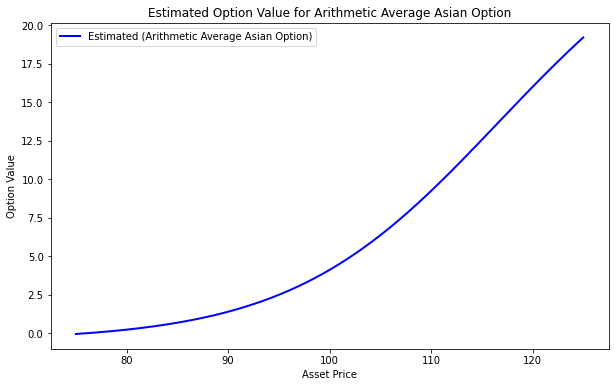

Training and comparing Barrier Option (Up-and-Out)
Epoch 0, Loss: 210.4879608154297
Epoch 1000, Loss: 168.47866821289062
Epoch 2000, Loss: 188.8509063720703
Epoch 3000, Loss: 169.46290588378906
Epoch 4000, Loss: 173.52984619140625


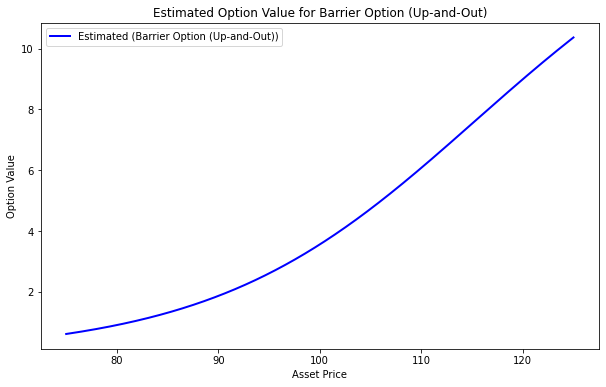

Training and comparing Lookback Option (Floating Strike)
Epoch 0, Loss: 1197.385498046875
Epoch 1000, Loss: 649.1986083984375
Epoch 2000, Loss: 623.4244995117188
Epoch 3000, Loss: 622.4219970703125
Epoch 4000, Loss: 623.3075561523438


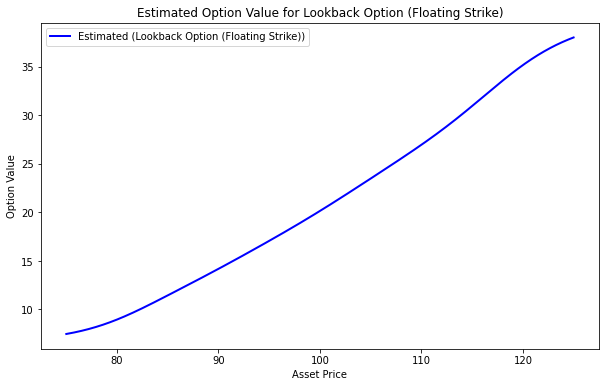

Training and comparing Chooser Option
Epoch 0, Loss: 843.2771606445312
Epoch 1000, Loss: 313.3115539550781
Epoch 2000, Loss: 302.41314697265625
Epoch 3000, Loss: 309.2192077636719
Epoch 4000, Loss: 340.1257019042969


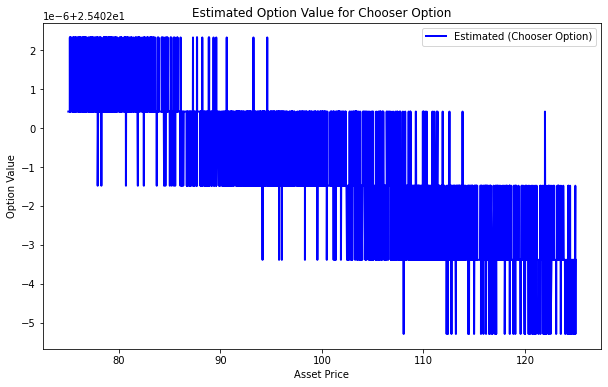

Training and comparing Compound Option
Epoch 0, Loss: 4.846865177154541
Epoch 1000, Loss: 1.6328954696655273
Epoch 2000, Loss: 0.7623905539512634
Epoch 3000, Loss: 4.085680961608887
Epoch 4000, Loss: 1.721838116645813


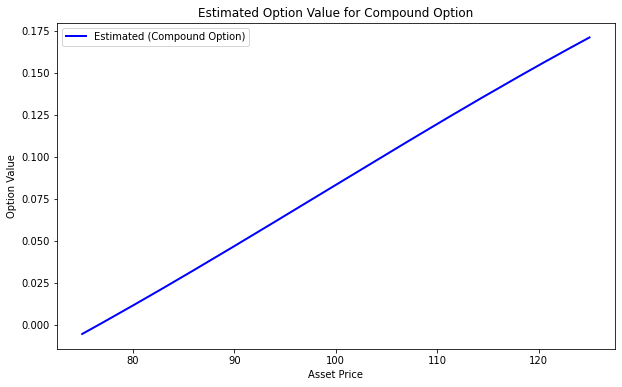

In [4]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Set data type
DTYPE = 'float32'
tf.keras.backend.set_floatx(DTYPE)

# Final time
T = tf.constant(2., dtype=DTYPE)

# Interest rate
r = tf.constant(1./20, dtype=DTYPE)

# Drift
mu = tf.constant(-1./20, dtype=DTYPE)

# Strike price
K = tf.constant(100., dtype=DTYPE)

# Diffusion/volatility
sigma = tf.constant(0.2, dtype=DTYPE)  # Fixed volatility for simplicity

# Domain-of-interest for asset price at t=0
a = tf.constant(75., dtype=DTYPE)
b = tf.constant(125., dtype=DTYPE)

# Define model for single asset
def init_model(num_hidden_neurons=100, num_hidden_layers=2):
    model = tf.keras.Sequential()
    model.add(tf.keras.layers.Input(shape=(1,)))
    for _ in range(num_hidden_layers):
        model.add(tf.keras.layers.Dense(num_hidden_neurons, activation='tanh'))
    model.add(tf.keras.layers.Dense(1, activation=None))
    return model

# Choose an optimizer
optimizer = tf.keras.optimizers.Adam(1e-3)

# Training and loss function
@tf.function  # Optimizes the loss computation
def loss_fn(X, y, model):
    y_pred = model(X)
    return tf.reduce_mean(tf.math.squared_difference(y, y_pred))

@tf.function  # Optimizes gradient computation
def compute_grad(X, y, model):
    with tf.GradientTape() as tape:
        loss = loss_fn(X, y, model)
    grad = tape.gradient(loss, model.trainable_variables)
    return loss, grad

# Monte Carlo path generation for options (single-asset)
@tf.function  # Optimizes the path generation
def draw_X(num_samples, a, b, time_steps):
    """ Generate Monte Carlo paths for a single asset. """
    X0 = a + tf.random.uniform((num_samples, 1), dtype=DTYPE) * (b - a)
    dt = T / time_steps
    X_paths = [X0]
    for t in range(time_steps):
        xi = tf.random.normal(shape=(num_samples, 1), dtype=DTYPE)
        X_new = X_paths[-1] * tf.exp((mu - tf.square(sigma)/2) * dt + sigma * tf.sqrt(dt) * xi)
        X_paths.append(X_new)
    return tf.stack(X_paths, axis=2)

### Arithmetic Average Asian Option
def fun_g_asian(x):
    # Reduce the mean across the time dimension, and remove unnecessary dimensions
    avg_price = tf.reduce_mean(x, axis=2)
    return tf.maximum(avg_price - K, 0.)  # The shape will be (number_of_samples,)

### Barrier Option (Up-and-Out)
B = tf.constant(120., dtype=DTYPE)
def fun_g_barrier(x):
    terminal_price = x[:, :, -1]
    has_breached = tf.reduce_max(x, axis=2, keepdims=True) >= B
    return tf.where(has_breached, tf.zeros_like(terminal_price), tf.maximum(terminal_price - K, 0.))

### Lookback Option (Floating Strike)
def fun_g_lookback(x):
    min_price = tf.reduce_min(x, axis=2, keepdims=True)
    terminal_price = x[:, :, -1]
    return tf.maximum(terminal_price - min_price, 0.)

### Chooser Option
def fun_g_chooser(x):
    terminal_price = x[:, :, -1]
    call_payoff = tf.maximum(terminal_price - K, 0.)
    put_payoff = tf.maximum(K - terminal_price, 0.)
    return tf.maximum(call_payoff, put_payoff)

### Compound Option
def fun_g_compound(x, strike_option):
    terminal_price = x[:, :, -1]
    option_price = tf.maximum(terminal_price - strike_option, 0.)
    return tf.maximum(option_price - K, 0.)


# Training loop
# Training loop without @tf.function
def train_step(option_fun_g, model, num_epochs=5000, batch_size=4000, time_steps=150):
    for i in range(num_epochs):
        X = draw_X(batch_size, a, b, time_steps)
        y = option_fun_g(X)
        loss, grad = compute_grad(X[:, :, 0], y, model)
        optimizer.apply_gradients(zip(grad, model.trainable_variables))
        if i % 1000 == 0:
            # Print actual loss value
            print(f"Epoch {i}, Loss: {loss.numpy()}")


# Plotting function 
def plot_solution(option_fun_g, model, option_name, time_steps=150, num_samples=4000):
    # Generate Monte Carlo paths for plotting
    X = draw_X(num_samples, a, b, time_steps)
    
    # Estimated option value from the model (Neural Network)
    u_pred = model(X[:, :, 0], training=False).numpy()

    # Sort values based on asset price for better plotting
    sorted_indices = np.argsort(X[:, 0, 0].numpy().flatten())
    X_sorted = X[:, 0, 0].numpy().flatten()[sorted_indices]
    u_pred_sorted = u_pred.flatten()[sorted_indices]

    # Plot only estimated (predicted) values
    plt.figure(figsize=(10, 6))
    plt.plot(X_sorted, u_pred_sorted, label=f'Estimated ({option_name})', color='b', lw=2)

    plt.title(f'Estimated Option Value for {option_name}')
    plt.xlabel('Asset Price')
    plt.ylabel('Option Value')
    plt.legend()
    plt.savefig(f'{option_name}_estimated_option_value.png', format='png')
    plt.show()


# Function to train and plot for each option
def run_option(option_fun_g, option_name, strike_option=None):
    # Initialize a new model for each option to avoid parameter interference
    model = init_model()

    print(f"Training and comparing {option_name}")
    train_step(option_fun_g, model)

    if strike_option is not None:
        plot_solution(lambda x: fun_g_compound(x, strike_option), model, option_name)
    else:
        plot_solution(option_fun_g, model, option_name)


# Train and plot for each option with both estimated and real values
run_option(fun_g_asian, "Arithmetic Average Asian Option")
run_option(fun_g_barrier, "Barrier Option (Up-and-Out)")
run_option(fun_g_lookback, "Lookback Option (Floating Strike)")
run_option(fun_g_chooser, "Chooser Option")

# For Compound Option, we pass the strike price
strike_option = tf.constant(105., dtype=DTYPE)
run_option(lambda x: fun_g_compound(x, strike_option), "Compound Option", strike_option=strike_option)

